# Training and evaluation

Cross-validated comparison of registered models on both systems, and hyperparameter search with scikit-learn tools.

In [1]:
import pandas as pd
import tranpy
from tranpy_core import ExperimentSpec, ModelConfig, run_experiment
from tranpy_core.models import available_models
from pathlib import Path
import matplotlib.pyplot as plt
from tranpy_core.plotting import publication_style, save_figure

FIGURES = Path("outputs")
plt.rcParams["figure.dpi"] = 150

In [2]:
available_models(installed_only=True)

('adaboost',
 'decision_tree',
 'dense_network',
 'dummy',
 'extra_trees',
 'gaussian_nb',
 'gaussian_process',
 'gradient_boosting',
 'knn',
 'lda',
 'lightgbm',
 'logistic_regression',
 'lstm_network',
 'mlp',
 'qda',
 'random_forest',
 'ridge',
 'sgd',
 'svm',
 'tcn_network',
 'transformer_network',
 'xgboost')

## One experiment per system

In [3]:
models = ["logistic_regression", "lda", "knn", "svm", "mlp", "random_forest", "extra_trees", "gradient_boosting"]
spec = ExperimentSpec(name="comparison", models=tuple(ModelConfig(m) for m in models), cv_folds=5, seed=0)

results = {key: run_experiment(spec, tranpy.load_snapshots(key)) for key in ("ieee_9bus", "new_england")}

In [4]:
table = pd.DataFrame([
    {"system": key, "model": m, **{k: s[k] for k in ("accuracy_mean", "accuracy_std", "roc_auc_mean")},
     "test_accuracy": r.test_scores[m].accuracy}
    for key, r in results.items() for m, s in r.cv_summary.items()
])
table.round(4)

,system,model,accuracy_mean,accuracy_std,roc_auc_mean,test_accuracy
0,ieee_9bus,logistic_regression,0.9702,0.0061,0.9953,0.967
1,ieee_9bus,lda,0.9670,0.0076,0.9948,0.948
2,ieee_9bus,knn,0.9872,0.0027,0.9965,0.979
3,ieee_9bus,svm,0.9725,0.0040,0.9966,0.968
4,ieee_9bus,mlp,0.9845,0.0048,0.9986,0.981
5,ieee_9bus,random_forest,0.9905,0.0034,0.9988,0.984
6,ieee_9bus,extra_trees,0.9905,0.0036,0.9991,0.988
7,ieee_9bus,gradient_boosting,0.9885,0.0027,0.9987,0.984
8,new_england,logistic_regression,0.9685,0.0041,0.9932,0.971
9,new_england,lda,0.9658,0.0034,0.9941,0.970


## Cross-validated accuracy

Dots show the mean over 5 folds, lines one standard deviation.

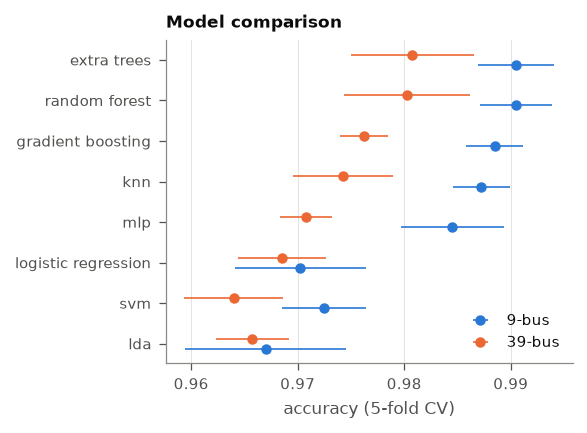

In [5]:
from tranpy_core.plotting import CATEGORICAL, SECONDARY

order = table.groupby("model")["accuracy_mean"].mean().sort_values().index
with publication_style():
    fig, ax = plt.subplots(figsize=(3.5, 2.8))
    for i, (key, label) in enumerate([("ieee_9bus", "9-bus"), ("new_england", "39-bus")]):
        part = table[table.system == key].set_index("model").loc[order]
        y = range(len(order))
        offset = [v + (i - 0.5) * 0.25 for v in y]
        ax.errorbar(part.accuracy_mean, offset, xerr=part.accuracy_std, fmt="o", ms=4,
                    color=CATEGORICAL[i], elinewidth=0.8, label=label)
    ax.set_yticks(range(len(order)), [m.replace("_", " ") for m in order])
    ax.grid(axis="y", visible=False)
    ax.set_xlabel("accuracy (5-fold CV)")
    ax.legend(loc="lower right")
    ax.set_title("Model comparison")
    save_figure(fig, FIGURES / "03_model_comparison.pdf")
plt.show()

## Hyperparameter search

Registry pipelines are ordinary scikit-learn objects.

In [6]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from tranpy_core import make_pipeline, train_test_split

data = tranpy.load_ieee_9bus()
split = train_test_split(data.labels, test_size=0.2, seed=42)
search = GridSearchCV(make_pipeline("svm", seed=0), {"model__C": [0.3, 1, 3, 10], "model__gamma": ["scale", 0.05]},
                      cv=StratifiedKFold(5, shuffle=True, random_state=0), scoring="roc_auc")
search.fit(data.features[split.train], data.labels[split.train])
search.best_params_, round(search.best_score_, 4)

({'model__C': 10, 'model__gamma': 'scale'}, np.float64(0.998))